# Лабораторная работа
## Анализ и прогнозирование временных рядов на примере розничных продаж

Выполнил: Лопаткин Дмитрий Кириллович М8О-203СВ-25

### Подготовка окружения

Если библиотек нет, их можно установить командой:

`pip install pandas numpy matplotlib seaborn scipy statsmodels scikit-learn PyWavelets`

Ячейка ниже только импортирует библиотеки и задаёт единый стиль графиков

In [1]:
from pathlib import Path
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pywt

from IPython.display import display
from scipy import stats
from scipy.fft import rfft, rfftfreq
from scipy.signal import detrend
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RANDOM_STATE = 42

## 1. Загрузка и проверка данных

Ряд должен иметь правильный временной индекс и одинаковый шаг. Данные месячные, поэтому после загрузки задаём частоту `MS` - начало месяца. Также проверяем пропуски, дубли и типы столбцов

In [ ]:
DATA_PATH = Path("retail_sales_mock_data.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Положите retail_sales_mock_data.csv в одну папку с ноутбуком."
    )

df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df = df.sort_values("Date").set_index("Date").asfreq("MS")

print(f"Размер таблицы: {df.shape}")
print(f"Период: {df.index.min().date()} - {df.index.max().date()}")
print(f"Пропуски: {df.isna().sum().sum()}")
print(f"Дубли дат: {df.index.duplicated().sum()}")
display(df.head())
display(df.dtypes.to_frame("Тип данных"))

Размер таблицы: (48, 3)
Период: 2020-01-01 — 2023-12-01
Пропуски: 0
Дубли дат: 0


,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0


,Тип данных
SalesAmount,int64
Promotion,int64
HolidayMonth,int64


In [ ]:
# Проверим, что после задания месячной частоты не появились пропущенные даты
expected_dates = pd.date_range(df.index.min(), df.index.max(), freq="MS")
quality_table = pd.DataFrame({
    "Проверка": ["Число наблюдений", "Ожидаемое число месяцев", "Пропуски", "Дубли дат"],
    "Результат": [len(df), len(expected_dates), int(df.isna().sum().sum()), int(df.index.duplicated().sum())]
})
display(quality_table)

,Проверка,Результат
0,Число наблюдений,48
1,Ожидаемое число месяцев,48
2,Пропуски,0
3,Дубли дат,0


### Вывод по пункту 1

В таблице 48 ежемесячных наблюдений за 2020–2023 годы. Пропусков, повторяющихся дат и разрывов в календаре нет. Целевая переменная - `SalesAmount`, а `Promotion` и `HolidayMonth` можно использовать как внешние признаки в SARIMAX. Дополнительное заполнение или удаление строк не требуется

## 2. Разведочный анализ данных (EDA)

Сначала посмотрим на динамику продаж, скользящее среднее, месячный профиль, распределение и связь продаж с акциями и праздничным месяцем

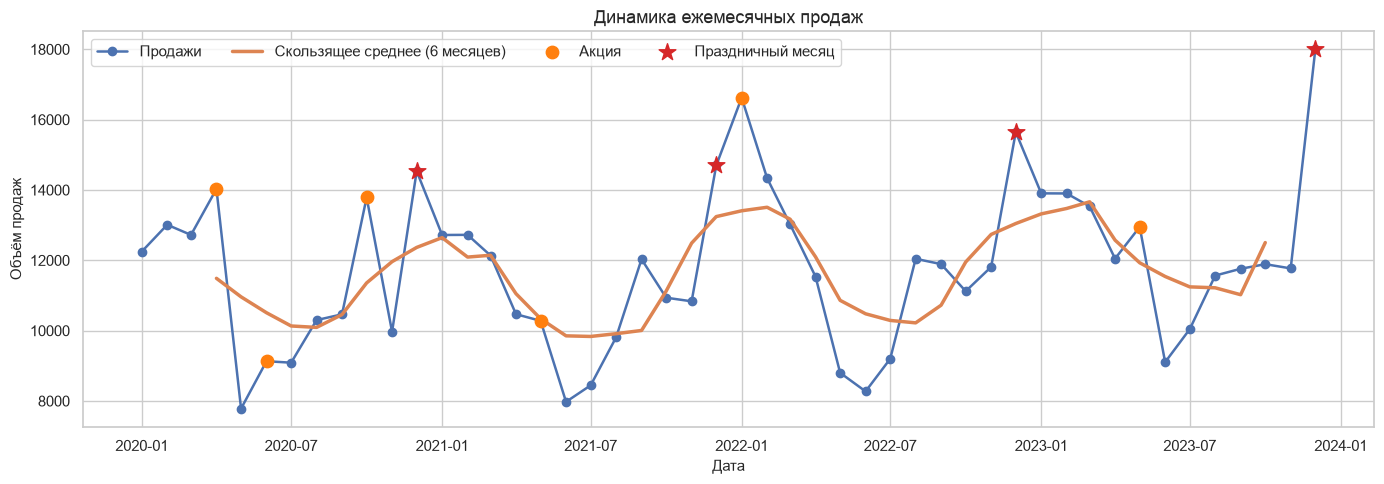

In [4]:
y = df["SalesAmount"].astype(float)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y.index, y, marker="o", linewidth=1.8, label="Продажи")
ax.plot(y.rolling(6, center=True).mean(), linewidth=2.5, label="Скользящее среднее (6 месяцев)")
ax.scatter(df.index[df["Promotion"] == 1], y[df["Promotion"] == 1],
           color="tab:orange", s=80, label="Акция", zorder=3)
ax.scatter(df.index[df["HolidayMonth"] == 1], y[df["HolidayMonth"] == 1],
           color="tab:red", marker="*", s=160, label="Праздничный месяц", zorder=4)
ax.set(title="Динамика ежемесячных продаж", xlabel="Дата", ylabel="Объём продаж")
ax.legend(ncol=4)
plt.tight_layout()
plt.show()

In [ ]:
# Описательные статистики и коэффициент вариации
summary = y.describe().to_frame("SalesAmount")
summary.loc["cv"] = y.std() / y.mean()
display(summary)

# IQR используем только для поиска возможных выбросов, но не удаляем их автоматически
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = df[(y < lower_bound) | (y > upper_bound)]

print(f"Границы IQR: {lower_bound:,.1f} — {upper_bound:,.1f}")
display(outliers)

,SalesAmount
count,48.000
mean,"11,768.542"
std,"2,257.545"
min,"7,783.000"
25%,"10,219.750"
50%,"11,851.000"
75%,"13,014.000"
max,"17,996.000"
cv,0.192


Границы IQR: 6,028.4 — 17,205.4


,SalesAmount,Promotion,HolidayMonth
Date,,,
2023-12-01,17996,0,1


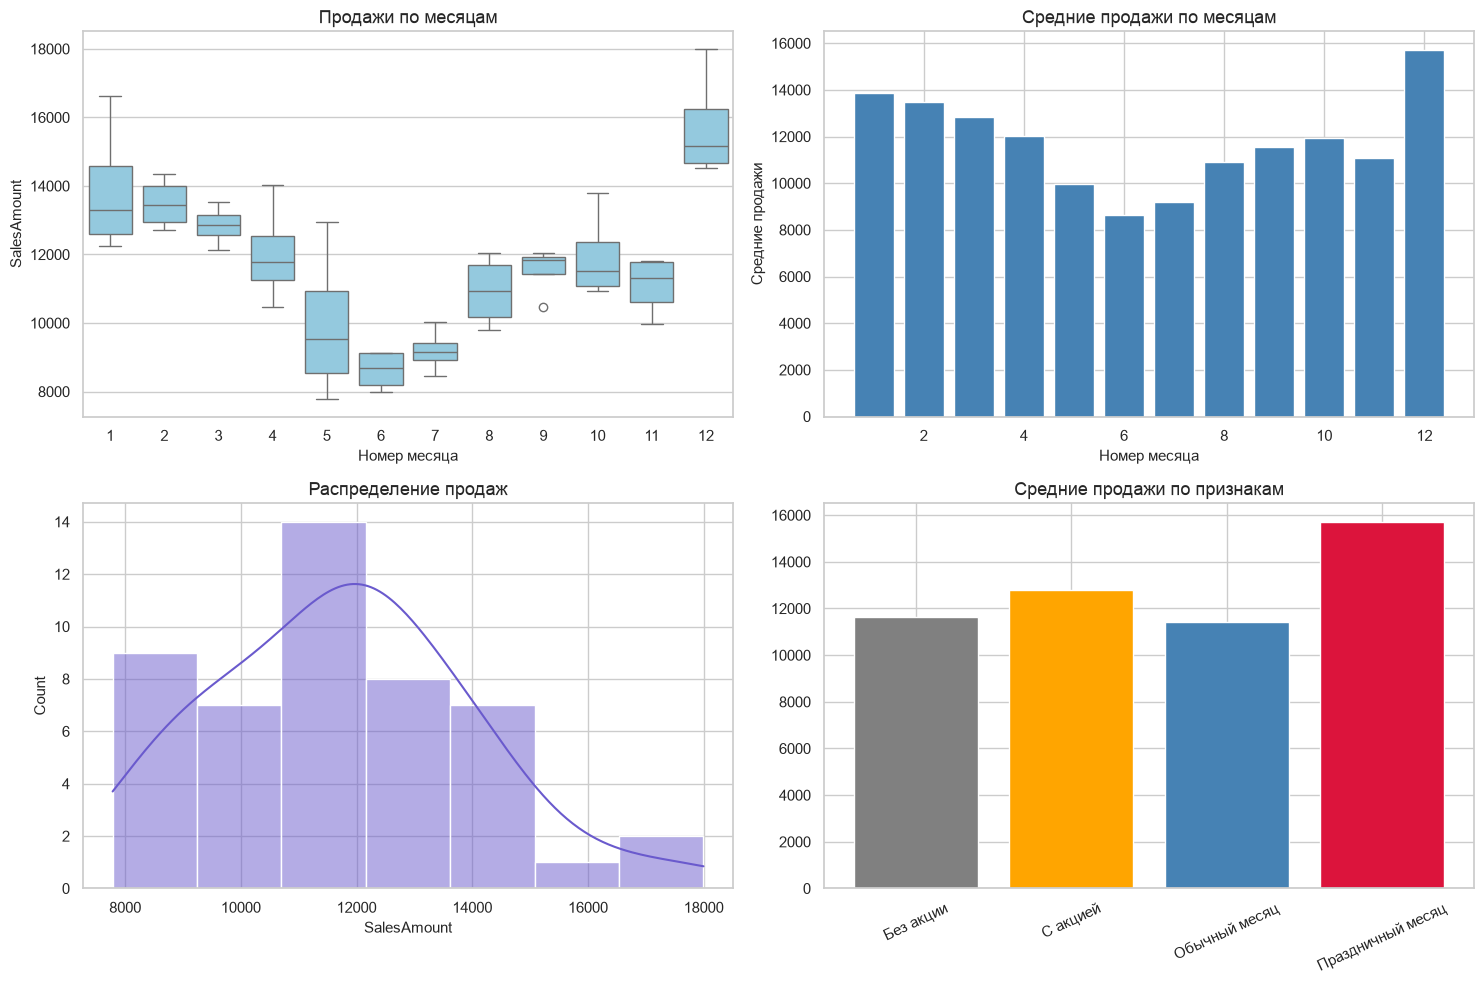

,Средние продажи
Без акции,"11,621.238"
С акцией,"12,799.667"
Обычный месяц,"11,409.523"
Праздничный месяц,"15,717.750"


In [6]:
eda = df.assign(
    Year=df.index.year,
    Month=df.index.month,
    MonthName=df.index.strftime("%b")
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.boxplot(data=eda, x="Month", y="SalesAmount", ax=axes[0, 0], color="skyblue")
axes[0, 0].set_title("Продажи по месяцам")
axes[0, 0].set_xlabel("Номер месяца")

monthly_mean = eda.groupby("Month")["SalesAmount"].mean()
axes[0, 1].bar(monthly_mean.index, monthly_mean.values, color="steelblue")
axes[0, 1].set_title("Средние продажи по месяцам")
axes[0, 1].set_xlabel("Номер месяца")
axes[0, 1].set_ylabel("Средние продажи")

sns.histplot(y, kde=True, ax=axes[1, 0], color="slateblue")
axes[1, 0].set_title("Распределение продаж")

group_means = pd.DataFrame({
    "Без акции": [df.loc[df["Promotion"] == 0, "SalesAmount"].mean()],
    "С акцией": [df.loc[df["Promotion"] == 1, "SalesAmount"].mean()],
    "Обычный месяц": [df.loc[df["HolidayMonth"] == 0, "SalesAmount"].mean()],
    "Праздничный месяц": [df.loc[df["HolidayMonth"] == 1, "SalesAmount"].mean()]
}).T
axes[1, 1].bar(group_means.index, group_means[0], color=["gray", "orange", "steelblue", "crimson"])
axes[1, 1].set_title("Средние продажи по признакам")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()
display(group_means.rename(columns={0: "Средние продажи"}))

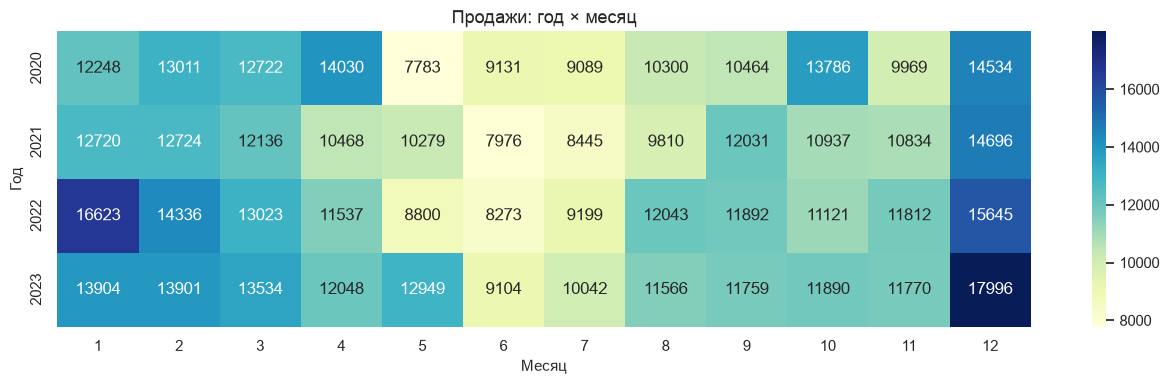

In [ ]:
# Тепловая карта хорошо показывает повторяемость месячного рисунка по годам
heatmap_data = eda.pivot(index="Year", columns="Month", values="SalesAmount")
plt.figure(figsize=(13, 4))
sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Продажи: год × месяц")
plt.xlabel("Месяц")
plt.ylabel("Год")
plt.tight_layout()
plt.show()

### Стационарность, ACF и PACF

На занятиях использовались ADF-тест и графики ACF/PACF. В ADF нулевая гипотеза означает нестационарность. В KPSS, наоборот, нулевая гипотеза означает стационарность. Совместное использование двух тестов делает вывод надёжнее

In [8]:
def stationarity_tests(series, name):
    # Возвращает основные результаты ADF и KPSS в одной строке.
    series = series.dropna()
    adf_result = adfuller(series, autolag="AIC")
    kpss_result = kpss(series, regression="c", nlags="auto")
    return {
        "Ряд": name,
        "ADF statistic": adf_result[0],
        "ADF p-value": adf_result[1],
        "KPSS statistic": kpss_result[0],
        "KPSS p-value": kpss_result[1]
    }

stationarity = pd.DataFrame([
    stationarity_tests(y, "Исходный ряд"),
    stationarity_tests(y.diff(), "Первая разность"),
    stationarity_tests(y.diff(12), "Сезонная разность (12)")
])
display(stationarity)

,Ряд,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value
0,Исходный ряд,-4.514,0.000,0.139,0.100
1,Первая разность,-5.630,0.000,0.097,0.100
2,Сезонная разность (12),-3.626,0.005,0.217,0.100


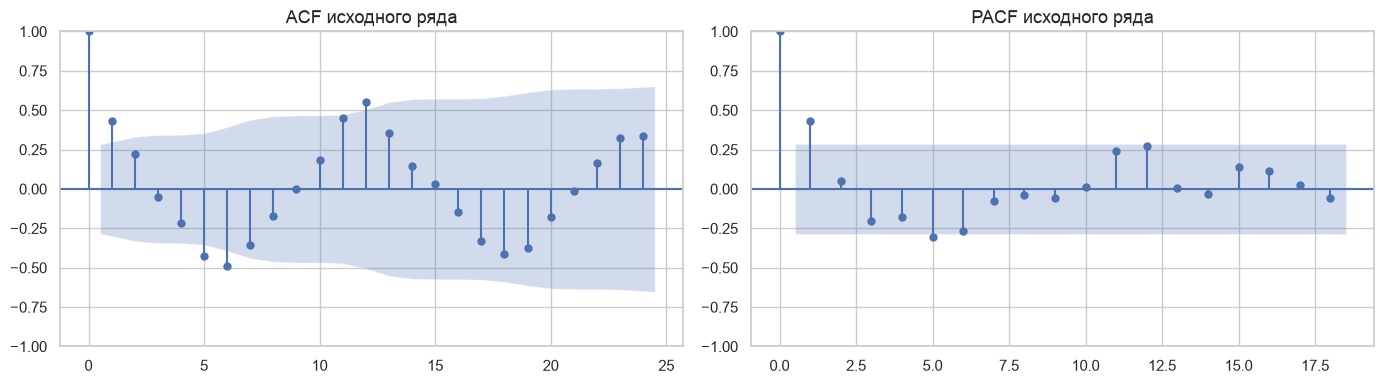

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y, lags=24, ax=axes[0])
plot_pacf(y, lags=18, method="ywm", ax=axes[1])
axes[0].set_title("ACF исходного ряда")
axes[1].set_title("PACF исходного ряда")
plt.tight_layout()
plt.show()

### Вывод по пункту 2

Средний объём продаж равен примерно 11,8 тыс., коэффициент вариации - около 19%. Самые высокие средние значения наблюдаются в декабре, январе и феврале, а минимум - в июне и июле. В декабре среднее заметно выше обычных месяцев. Признак акции также связан с повышенными продажами, но таких наблюдений всего шесть, поэтому вывод нужно считать осторожным.

IQR отметил декабрь 2023 года как возможный выброс. Удалять его нельзя: это праздничный месяц и значение согласуется с бизнес-сезонностью. ADF (p < 0,001) и KPSS (p > 0,05) не противоречат стационарности вокруг среднего, однако ACF имеет заметный максимум на лаге 12. Поэтому для прогноза всё равно важно явно учитывать годовую сезонность.

## 3. Декомпозиция временного ряда

Период сезонности равен 12, потому что данные месячные и предполагаемый цикл годовой. Сначала сравним классическую аддитивную, классическую мультипликативную и STL-декомпозицию

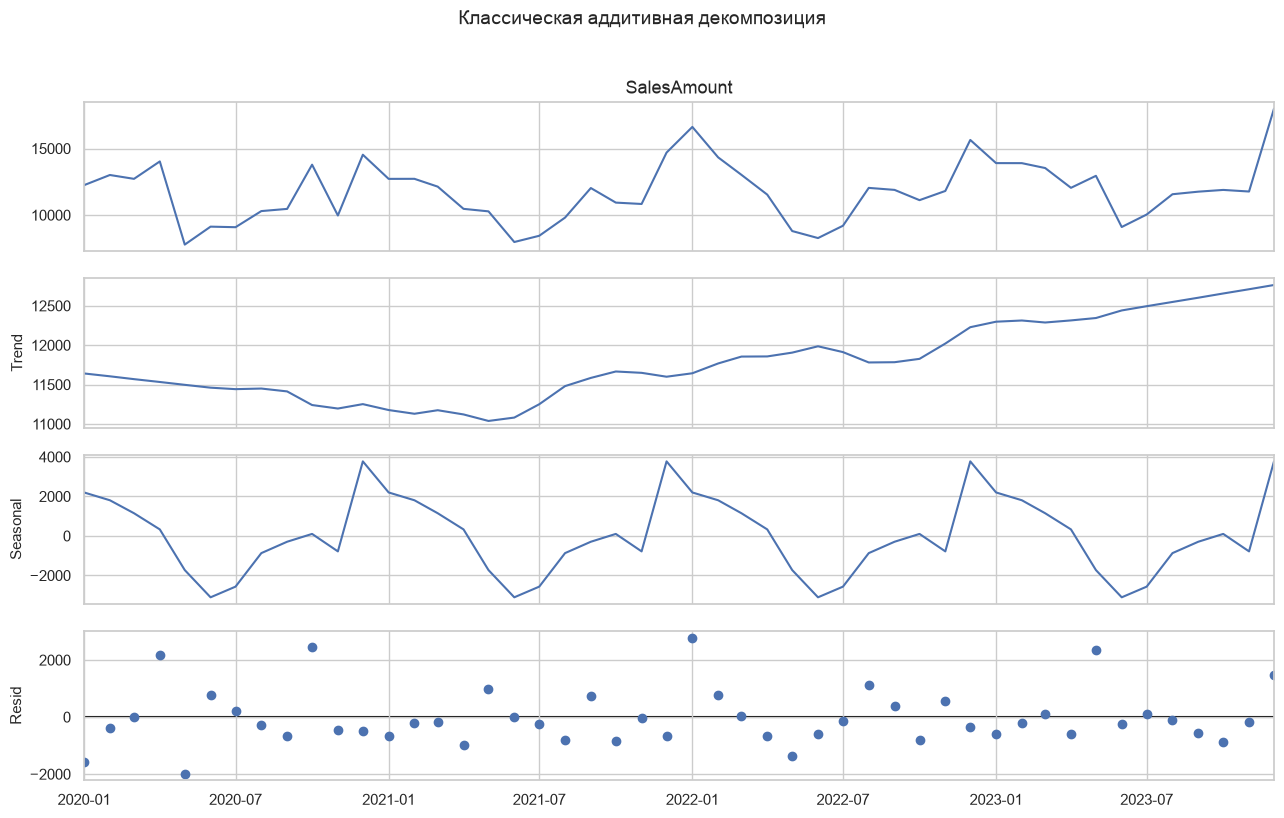

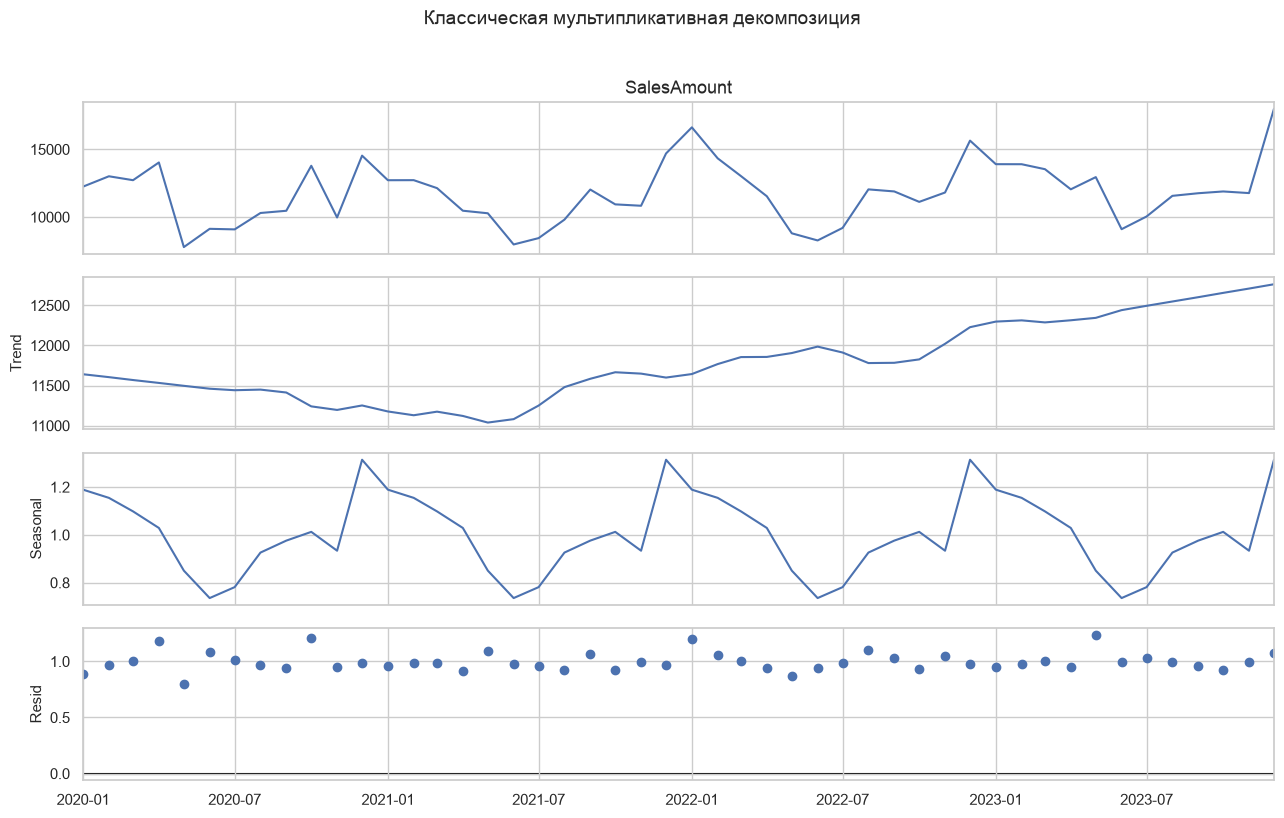

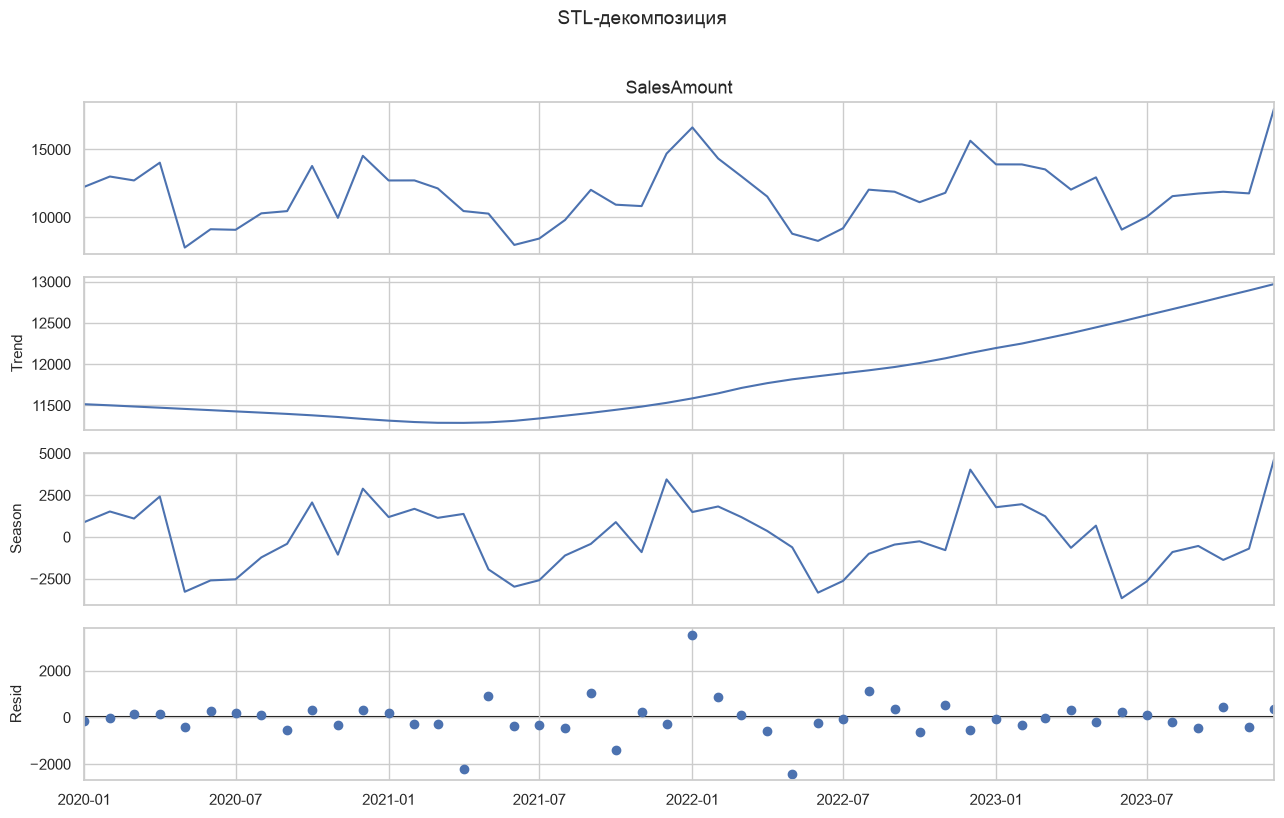

In [10]:
PERIOD = 12

additive = seasonal_decompose(
    y, model="additive", period=PERIOD, extrapolate_trend="freq"
)
multiplicative = seasonal_decompose(
    y, model="multiplicative", period=PERIOD, extrapolate_trend="freq"
)
stl = STL(y, period=PERIOD, seasonal=13, robust=True).fit()

for title, result in [
    ("Классическая аддитивная декомпозиция", additive),
    ("Классическая мультипликативная декомпозиция", multiplicative),
    ("STL-декомпозиция", stl)
]:
    fig = result.plot()
    fig.set_size_inches(13, 8)
    fig.suptitle(title, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

In [ ]:
def decomposition_strength(result, multiplicative=False):
    # Оценивает силу тренда и сезонности по отношению дисперсий
    if multiplicative:
        seasonal_part = (result.seasonal - 1) * result.trend
        remainder = (result.resid - 1) * result.trend
    else:
        seasonal_part = result.seasonal
        remainder = result.resid
    trend_part = result.trend
    season_strength = max(0, 1 - np.nanvar(remainder) / np.nanvar(seasonal_part + remainder))
    trend_strength = max(0, 1 - np.nanvar(remainder) / np.nanvar(trend_part + remainder))
    return season_strength, trend_strength

decomp_table = []
for name, result, is_mult in [
    ("Аддитивная", additive, False),
    ("Мультипликативная", multiplicative, True),
    ("STL", stl, False)
]:
    season_strength, trend_strength = decomposition_strength(result, is_mult)
    decomp_table.append({
        "Метод": name,
        "Сила сезонности": season_strength,
        "Сила тренда": trend_strength
    })

display(pd.DataFrame(decomp_table).set_index("Метод"))

,Сила сезонности,Сила тренда
Метод,,
Аддитивная,0.792,0.202
Мультипликативная,0.790,0.201
STL,0.853,0.282


### Спектральный анализ FFT

Перед FFT убираем линейный тренд и используем окно Ханна, чтобы уменьшить спектральную утечку. Чем выше амплитуда, тем сильнее соответствующая периодичность

,"Период, месяцев",Частота,Амплитуда
3,12.000,0.083,"30,670.702"
2,16.000,0.062,"19,080.520"
4,9.600,0.104,"17,998.720"
11,4.000,0.250,"10,177.042"
7,6.000,0.167,"10,004.500"
12,3.692,0.271,"9,197.668"


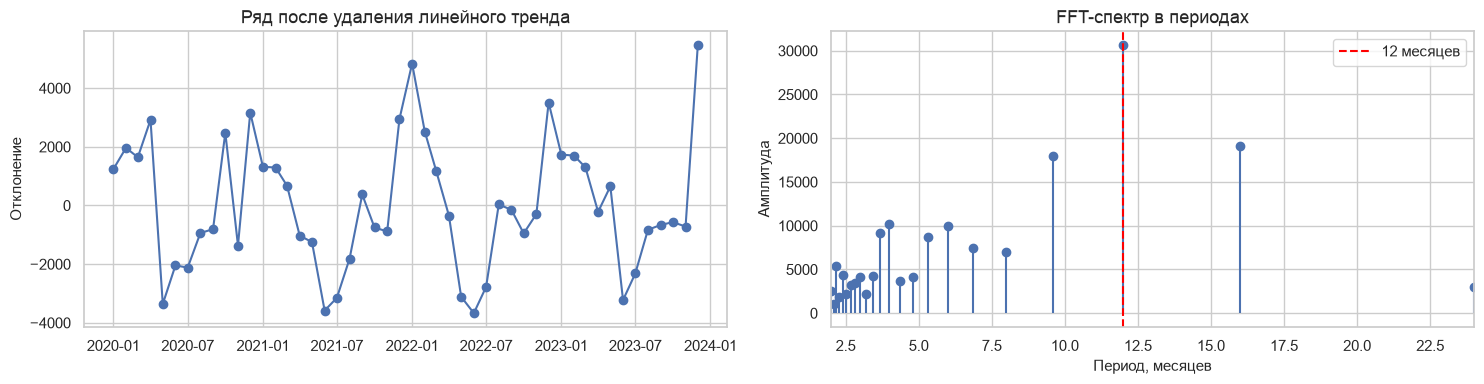

In [12]:
signal_detrended = detrend(y.values)
windowed_signal = signal_detrended * np.hanning(len(signal_detrended))

fft_values = rfft(windowed_signal)
frequencies = rfftfreq(len(windowed_signal), d=1)  # циклов в месяц
amplitudes = np.abs(fft_values)
amplitudes[0] = 0

positive = frequencies > 0
periods_fft = 1 / frequencies[positive]
amplitudes_fft = amplitudes[positive]

fft_peaks = pd.DataFrame({
    "Период, месяцев": periods_fft,
    "Частота": frequencies[positive],
    "Амплитуда": amplitudes_fft
}).sort_values("Амплитуда", ascending=False).head(6)
display(fft_peaks)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(y.index, signal_detrended, marker="o")
axes[0].set_title("Ряд после удаления линейного тренда")
axes[0].set_ylabel("Отклонение")

axes[1].stem(periods_fft, amplitudes_fft, basefmt=" ")
axes[1].axvline(12, color="red", linestyle="--", label="12 месяцев")
axes[1].set_xlim(2, 24)
axes[1].set_title("FFT-спектр в периодах")
axes[1].set_xlabel("Период, месяцев")
axes[1].set_ylabel("Амплитуда")
axes[1].legend()
plt.tight_layout()
plt.show()

### Вейвлет-анализ Морле

FFT показывает, какие периоды есть в ряду в среднем, но не показывает, когда они усиливаются или ослабевают. Непрерывное вейвлет-преобразование Морле показывает и период, и его изменение во времени

,"Период, месяцев",Средняя мощность
9,12.308,"31,571,510.878"
8,11.077,"29,153,307.262"
10,13.538,"23,433,917.506"
7,9.846,"17,185,110.013"
11,14.769,"12,882,089.947"
6,8.615,"6,775,046.208"


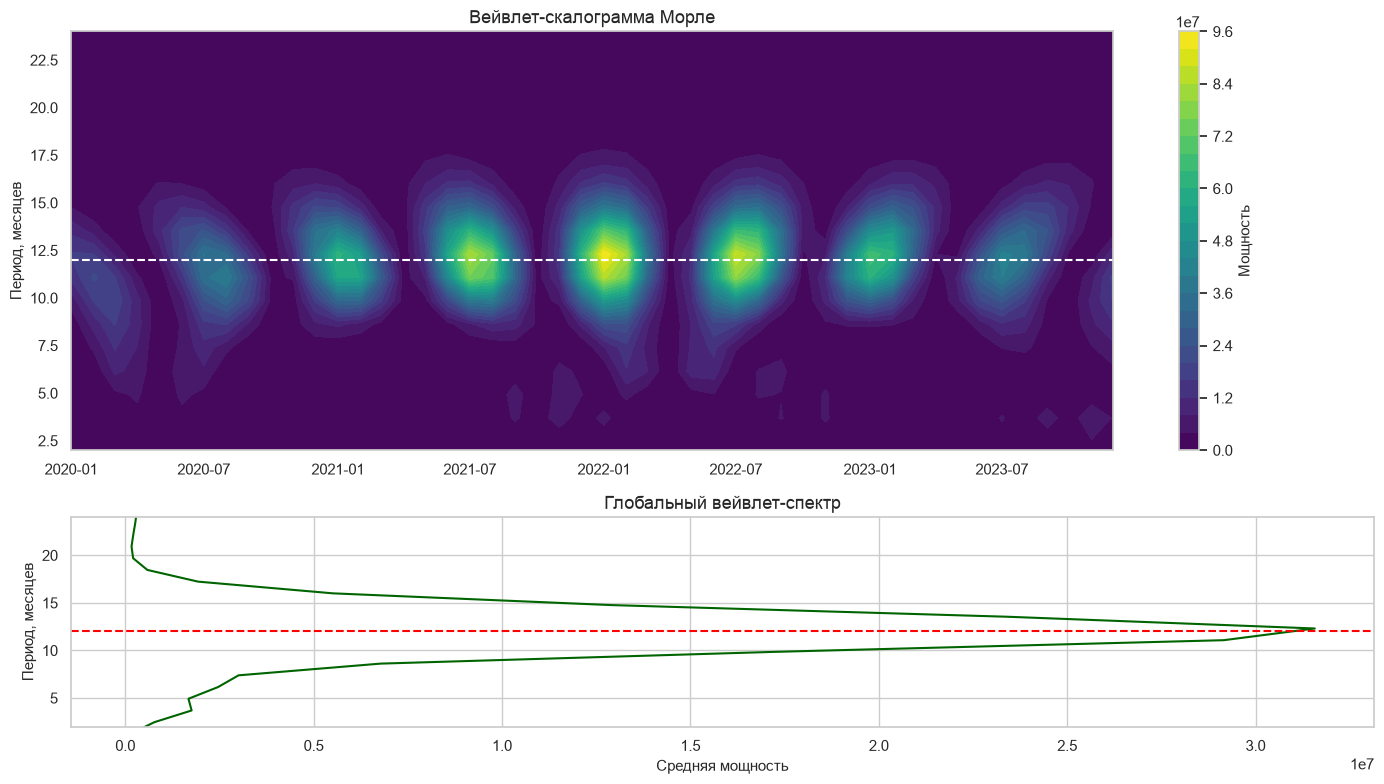

In [13]:
scales = np.arange(1, 33)
coefficients, wavelet_freqs = pywt.cwt(
    signal_detrended, scales, "morl", sampling_period=1
)
wavelet_periods = 1 / wavelet_freqs
wavelet_power = np.abs(coefficients) ** 2
global_wavelet_power = wavelet_power.mean(axis=1)

wavelet_peaks = pd.DataFrame({
    "Период, месяцев": wavelet_periods,
    "Средняя мощность": global_wavelet_power
}).sort_values("Средняя мощность", ascending=False).head(6)
display(wavelet_peaks)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={"height_ratios": [2, 1]})
contour = axes[0].contourf(
    y.index, wavelet_periods, wavelet_power, levels=30, cmap="viridis"
)
axes[0].axhline(12, color="white", linestyle="--", linewidth=1.5)
axes[0].set_ylim(2, 24)
axes[0].set_title("Вейвлет-скалограмма Морле")
axes[0].set_ylabel("Период, месяцев")
fig.colorbar(contour, ax=axes[0], label="Мощность")

axes[1].plot(global_wavelet_power, wavelet_periods, color="darkgreen")
axes[1].axhline(12, color="red", linestyle="--")
axes[1].set_ylim(2, 24)
axes[1].set_xlabel("Средняя мощность")
axes[1].set_ylabel("Период, месяцев")
axes[1].set_title("Глобальный вейвлет-спектр")

plt.tight_layout()
plt.show()

In [14]:
method_comparison = pd.DataFrame({
    "Метод": [
        "Аддитивная декомпозиция",
        "Мультипликативная декомпозиция",
        "STL",
        "FFT",
        "Вейвлет Морле"
    ],
    "Что показал": [
        "Стабильный годовой сезонный рисунок",
        "Похожий годовой рисунок в относительном масштабе",
        "Сильную сезонность и более устойчивые остатки",
        "Главный спектральный пик около 12 месяцев",
        "Максимальную среднюю мощность около 12 месяцев"
    ],
    "Преимущество": [
        "Простая интерпретация в исходных единицах",
        "Удобна, если амплитуда растёт вместе с уровнем",
        "Гибкая сезонность и устойчивость к выбросам",
        "Быстро находит глобальные периоды",
        "Показывает изменение периодов во времени"
    ],
    "Ограничение": [
        "Фиксированная сезонность",
        "Требует положительных значений и сложнее читать",
        "Нужен выбор периода и окна сглаживания",
        "Не локализует период во времени, чувствителен к короткому ряду",
        "Результат зависит от вейвлета и шкал"
    ]
})
display(method_comparison)

,Метод,Что показал,Преимущество,Ограничение
0,Аддитивная декомпозиция,Стабильный годовой сезонный рисунок,Простая интерпретация в исходных единицах,Фиксированная сезонность
1,Мультипликативная декомпозиция,Похожий годовой рисунок в относительном масштабе,"Удобна, если амплитуда растёт вместе с уровнем",Требует положительных значений и сложнее читать
2,STL,Сильную сезонность и более устойчивые остатки,Гибкая сезонность и устойчивость к выбросам,Нужен выбор периода и окна сглаживания
3,FFT,Главный спектральный пик около 12 месяцев,Быстро находит глобальные периоды,"Не локализует период во времени, чувствителен ..."
4,Вейвлет Морле,Максимальную среднюю мощность около 12 месяцев,Показывает изменение периодов во времени,Результат зависит от вейвлета и шкал


### Вывод по пункту 3

Все методы подтверждают годовую сезонность. Главный пик FFT соответствует периоду 12 месяцев, а максимум глобального вейвлет-спектра находится примерно на 12,3 месяца. Сила сезонности у STL около 0,85, что выше классической аддитивной и мультипликативной декомпозиции (около 0,79). Тренд выражен слабее сезонности.

Для этого ряда наиболее полезна STL: она устойчивее к декабрьскому пику 2023 года и допускает небольшое изменение сезонного рисунка. FFT удобно использовать для подтверждения периода, а вейвлет - для проверки его устойчивости во времени. Классические методы остаются самыми простыми для объяснения.

## 4. Построение прогнозных моделей

Последние 12 месяцев оставляем для финального теста. Это максимальный разумный горизонт для набора из 48 точек: в обучении остаётся 36 месяцев, то есть три полных годовых цикла. Горизонт 18 месяцев оставил бы только 2,5 цикла и сделал оценку сезонной модели ненадёжной.

Параметры выбираем без просмотра теста. Внутри обучающей части используем два последовательных окна: первые 24 месяца -> прогноз 6 месяцев и первые 30 месяцев -> прогноз ещё 6 месяцев. Перемешивать временной ряд нельзя.

Train: 2020-01-01 — 2022-12-01, n=36
Test:  2023-01-01 — 2023-12-01, n=12


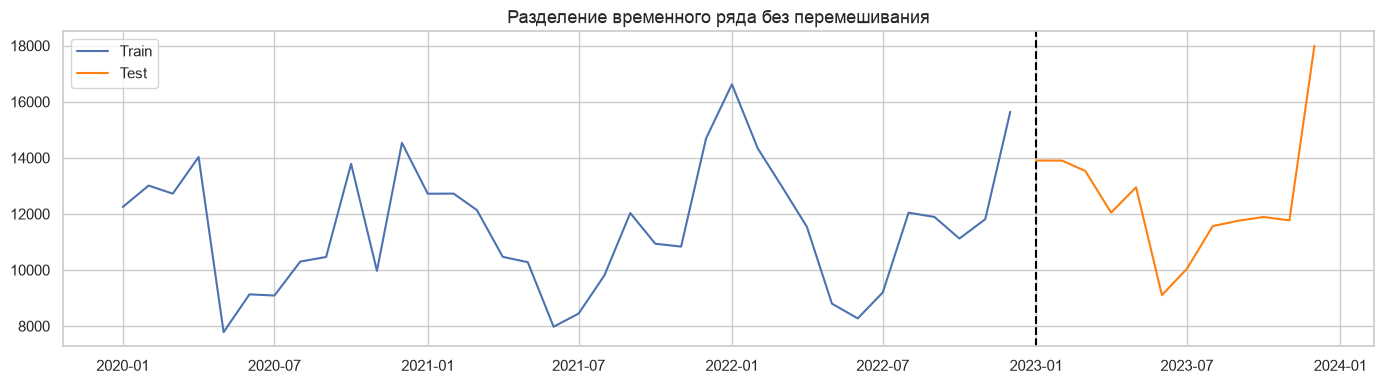

In [15]:
HORIZON = 12
target = df["SalesAmount"].astype(float)
exog = df[["Promotion", "HolidayMonth"]].astype(float)

y_train, y_test = target.iloc[:-HORIZON], target.iloc[-HORIZON:]
X_train, X_test = exog.iloc[:-HORIZON], exog.iloc[-HORIZON:]

print(f"Train: {y_train.index.min().date()} — {y_train.index.max().date()}, n={len(y_train)}")
print(f"Test:  {y_test.index.min().date()} — {y_test.index.max().date()}, n={len(y_test)}")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_train, label="Train")
ax.plot(y_test, label="Test", color="tab:orange")
ax.axvline(y_test.index[0], color="black", linestyle="--")
ax.set_title("Разделение временного ряда без перемешивания")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Небольшой список кандидатов оставляет код понятным и снижает риск переобучения
arima_candidates = [
    (0, 0, 0), (1, 0, 0), (0, 0, 1), (1, 0, 1),
    (0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1)
]

# По EDA фиксируем сезонное дифференцирование D=1 и период s=12
sarimax_candidates = [
    (order, (0, 1, 0, 12)) for order in arima_candidates
]

validation_folds = [(24, 6), (30, 6)]

def choose_arima(series, candidates):
    rows = []
    for order in candidates:
        fold_mse = []
        try:
            for train_size, horizon in validation_folds:
                model = ARIMA(
                    series.iloc[:train_size],
                    order=order,
                    trend="t" if order[1] == 1 else "ct"
                ).fit()
                prediction = model.forecast(horizon)
                actual = series.iloc[train_size:train_size + horizon]
                fold_mse.append(mean_squared_error(actual, prediction))
            rows.append({"order": order, "CV MSE": np.mean(fold_mse)})
        except Exception:
            continue
    return pd.DataFrame(rows).sort_values("CV MSE").reset_index(drop=True)

def choose_sarimax(series, features, candidates):
    rows = []
    for order, seasonal_order in candidates:
        fold_mse = []
        try:
            for train_size, horizon in validation_folds:
                model = SARIMAX(
                    series.iloc[:train_size],
                    exog=features.iloc[:train_size],
                    order=order,
                    seasonal_order=seasonal_order,
                    trend="t",
                    enforce_stationarity=False,
                    enforce_invertibility=False
                ).fit(disp=False, maxiter=200)
                prediction = model.forecast(
                    horizon,
                    exog=features.iloc[train_size:train_size + horizon]
                )
                actual = series.iloc[train_size:train_size + horizon]
                fold_mse.append(mean_squared_error(actual, prediction))
            rows.append({
                "order": order,
                "seasonal_order": seasonal_order,
                "CV MSE": np.mean(fold_mse)
            })
        except Exception:
            continue
    return pd.DataFrame(rows).sort_values("CV MSE").reset_index(drop=True)

arima_cv = choose_arima(y_train, arima_candidates)
sarimax_cv = choose_sarimax(y_train, X_train, sarimax_candidates)

display(arima_cv.head())
display(sarimax_cv.head())

,order,CV MSE
0,"(1, 0, 1)","5,812,192.640"
1,"(1, 0, 0)","5,828,632.383"
2,"(0, 0, 1)","5,961,580.404"
3,"(0, 0, 0)","6,857,048.816"
4,"(1, 1, 1)","15,710,191.821"


,order,seasonal_order,CV MSE
0,"(1, 1, 0)","(0, 1, 0, 12)","515,745.727"
1,"(1, 1, 1)","(0, 1, 0, 12)","561,461.802"
2,"(0, 1, 1)","(0, 1, 0, 12)","660,969.392"
3,"(0, 0, 1)","(0, 1, 0, 12)","727,408.434"
4,"(1, 0, 1)","(0, 1, 0, 12)","743,038.434"


In [17]:
best_arima_order = tuple(arima_cv.loc[0, "order"])
best_sarimax_order = tuple(sarimax_cv.loc[0, "order"])
best_seasonal_order = tuple(sarimax_cv.loc[0, "seasonal_order"])

arima_model = ARIMA(
    y_train,
    order=best_arima_order,
    trend="t" if best_arima_order[1] == 1 else "ct"
).fit()

sarimax_model = SARIMAX(
    y_train,
    exog=X_train,
    order=best_sarimax_order,
    seasonal_order=best_seasonal_order,
    trend="t",
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=200)

arima_forecast_obj = arima_model.get_forecast(HORIZON)
sarimax_forecast_obj = sarimax_model.get_forecast(HORIZON, exog=X_test)

arima_pred = arima_forecast_obj.predicted_mean
sarimax_pred = sarimax_forecast_obj.predicted_mean

print("Выбранная ARIMA:", best_arima_order)
print("Выбранная SARIMAX:", best_sarimax_order, "x", best_seasonal_order)

Выбранная ARIMA: (1, 0, 1)
Выбранная SARIMAX: (1, 1, 0) x (0, 1, 0, 12)


### Вывод по пункту 4

Внутренняя временная проверка выбрала ARIMA(1,0,1) и SARIMAX(1,1,0)×(0,1,0,12) с внешними признаками `Promotion` и `HolidayMonth`. Для SARIMAX годовое сезонное дифференцирование согласуется с EDA, ACF, FFT и вейвлет-анализом. Число параметров небольшое, что важно при 36 обучающих наблюдениях.

## 5. Оценка качества и анализ остатков

Для прогноза считаем MSE и R². Меньший MSE лучше. R² около 1 означает хорошее совпадение, около 0 - качество на уровне прогноза средним, отрицательное значение - хуже такого простого ориентира. AIC и BIC сравнивают качество подгонки с штрафом за сложность; меньше - лучше.

In [18]:
seasonal_naive = target.shift(12).loc[y_test.index]

comparison = pd.DataFrame([
    {
        "Модель": f"ARIMA{best_arima_order}",
        "MSE": mean_squared_error(y_test, arima_pred),
        "R²": r2_score(y_test, arima_pred),
        "AIC": arima_model.aic,
        "BIC": arima_model.bic
    },
    {
        "Модель": f"SARIMAX{best_sarimax_order}x{best_seasonal_order}",
        "MSE": mean_squared_error(y_test, sarimax_pred),
        "R²": r2_score(y_test, sarimax_pred),
        "AIC": sarimax_model.aic,
        "BIC": sarimax_model.bic
    },
    {
        "Модель": "Сезонный наивный прогноз",
        "MSE": mean_squared_error(y_test, seasonal_naive),
        "R²": r2_score(y_test, seasonal_naive),
        "AIC": np.nan,
        "BIC": np.nan
    }
]).sort_values("MSE").reset_index(drop=True)

comparison_for_display = comparison.copy()
comparison_for_display["MSE"] = comparison_for_display["MSE"].round(0)
comparison_for_display[["R²", "AIC", "BIC"]] = comparison_for_display[["R²", "AIC", "BIC"]].round(3)
display(comparison_for_display)

,Модель,MSE,R²,AIC,BIC
0,"SARIMAX(1, 1, 0)x(0, 1, 0, 12)","1,369,460.000",0.704,376.859,382.314
1,Сезонный наивный прогноз,"2,757,115.000",0.404,NaN,NaN
2,"ARIMA(1, 0, 1)","4,188,452.000",0.094,656.817,664.734


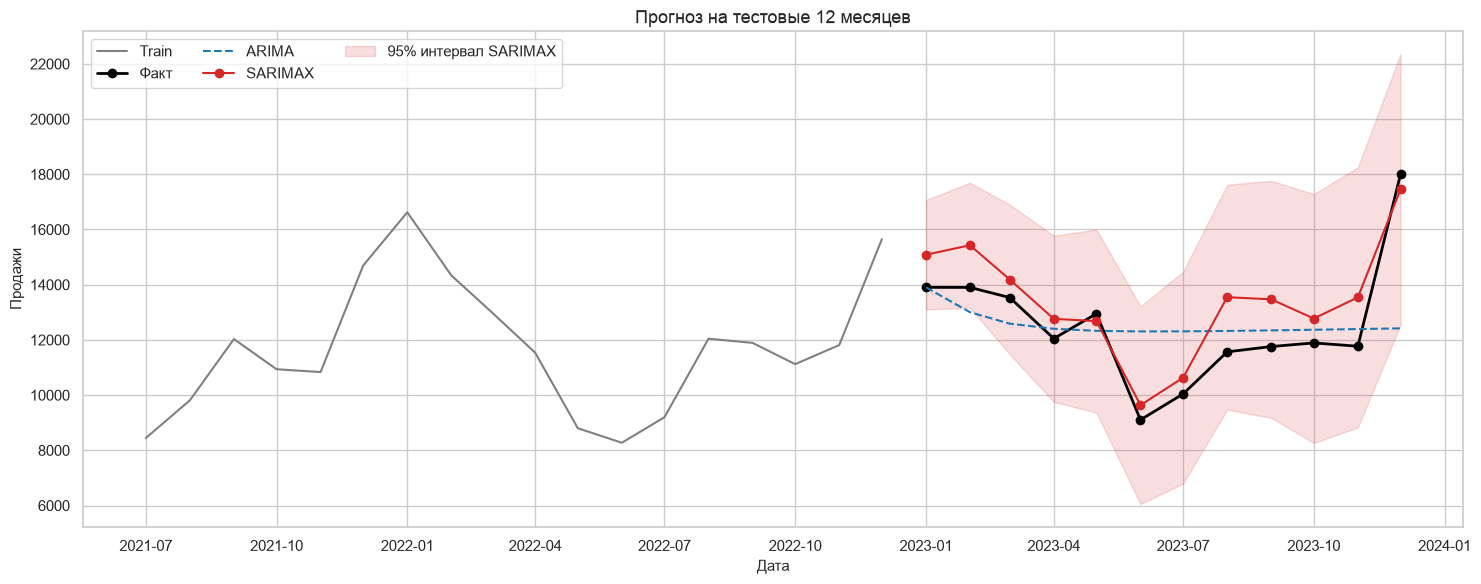

In [19]:
arima_ci = arima_forecast_obj.conf_int(alpha=0.05)
sarimax_ci = sarimax_forecast_obj.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(y_train.iloc[-18:], label="Train", color="gray")
ax.plot(y_test, label="Факт", color="black", marker="o", linewidth=2)
ax.plot(arima_pred, label="ARIMA", linestyle="--", color="tab:blue")
ax.plot(sarimax_pred, label="SARIMAX", color="tab:red", marker="o")
ax.fill_between(
    sarimax_ci.index,
    sarimax_ci.iloc[:, 0],
    sarimax_ci.iloc[:, 1],
    color="tab:red",
    alpha=0.15,
    label="95% интервал SARIMAX"
)
ax.set(title="Прогноз на тестовые 12 месяцев", xlabel="Дата", ylabel="Продажи")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

In [ ]:
def residual_diagnostics(model, name, minimum_burn=0):
    # Проверяет нормальность, автокорреляцию и гомоскедастичность остатков
    burn = max(getattr(model, "loglikelihood_burn", 0), minimum_burn)
    residuals = pd.Series(model.resid).iloc[burn:].dropna()
    lb_lag = min(8, max(1, len(residuals) // 3))
    arch_lags = min(4, max(1, len(residuals) // 5))

    lb_p = acorr_ljungbox(residuals, lags=[lb_lag], return_df=True)["lb_pvalue"].iloc[0]
    jb_stat, jb_p, skew, kurtosis = jarque_bera(residuals)
    arch_stat, arch_p, _, _ = het_arch(residuals, nlags=arch_lags)

    row = {
        "Модель": name,
        "Число остатков": len(residuals),
        "Ljung–Box p": lb_p,
        "Jarque–Bera p": jb_p,
        "ARCH p": arch_p,
        "Durbin–Watson": durbin_watson(residuals)
    }
    return row, residuals

arima_diag, arima_resid = residual_diagnostics(arima_model, "ARIMA")
sarimax_diag, sarimax_resid = residual_diagnostics(
    sarimax_model, "SARIMAX", minimum_burn=14
)

diagnostics = pd.DataFrame([arima_diag, sarimax_diag])
display(diagnostics)

print("Интерпретация p-value:")
print("p > 0.05 в Ljung–Box: значимая автокорреляция не обнаружена.")
print("p > 0.05 в Jarque–Bera: нормальность остатков не отвергается.")
print("p > 0.05 в ARCH: признаки меняющейся дисперсии не обнаружены.")

,Модель,Число остатков,Ljung–Box p,Jarque–Bera p,ARCH p,Durbin–Watson
0,ARIMA,36,0.139,0.965,0.103,1.857
1,SARIMAX,22,0.184,0.646,0.469,2.524


Интерпретация p-value:
p > 0.05 в Ljung–Box: значимая автокорреляция не обнаружена.
p > 0.05 в Jarque–Bera: нормальность остатков не отвергается.
p > 0.05 в ARCH: признаки меняющейся дисперсии не обнаружены.


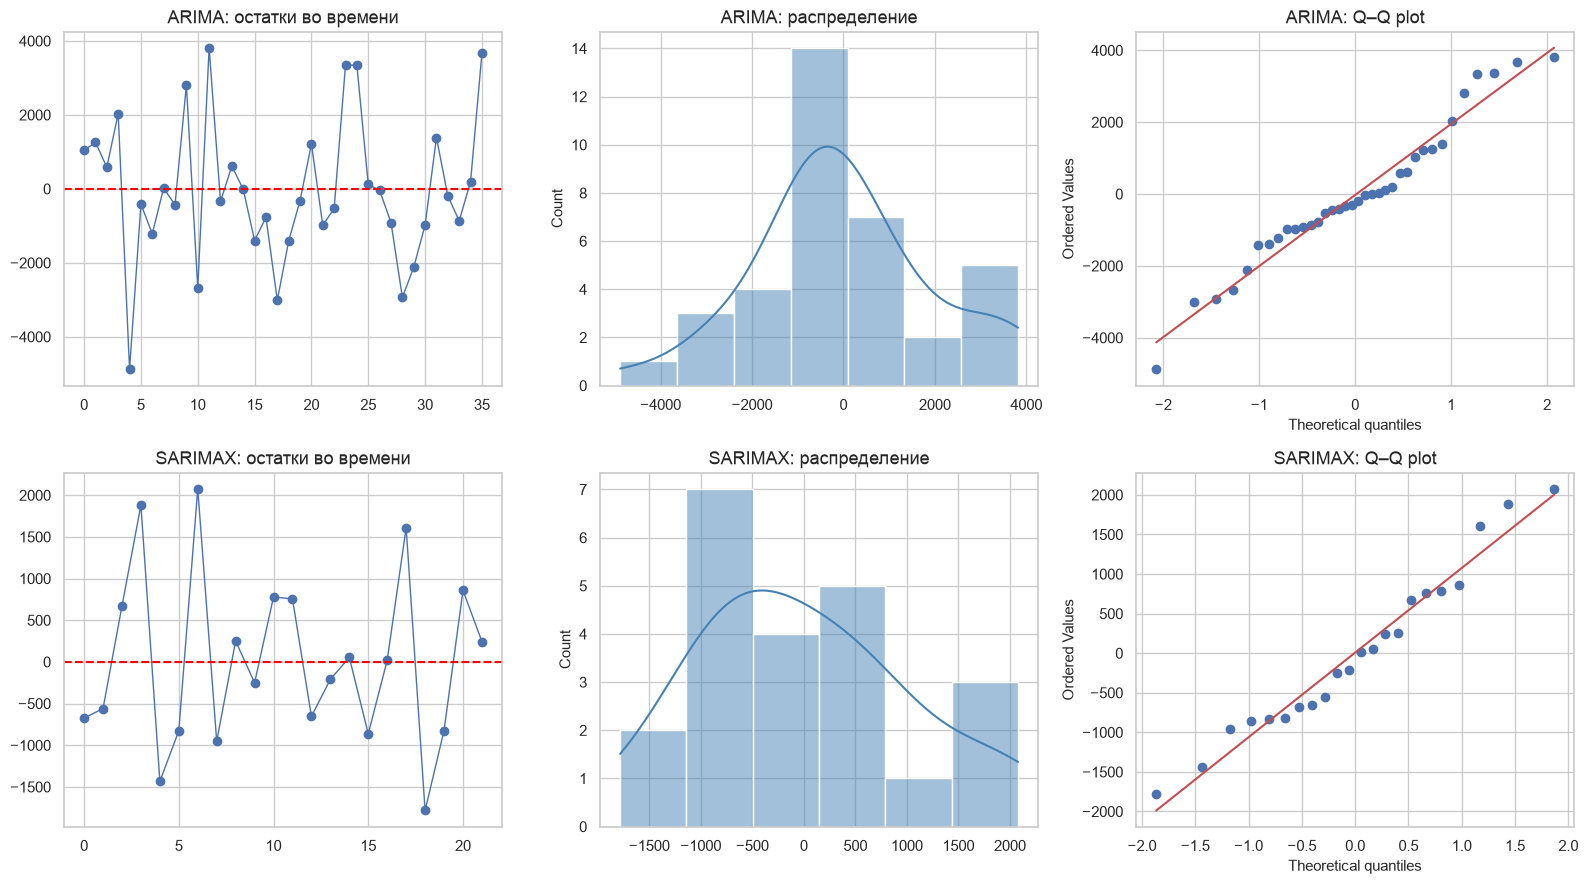

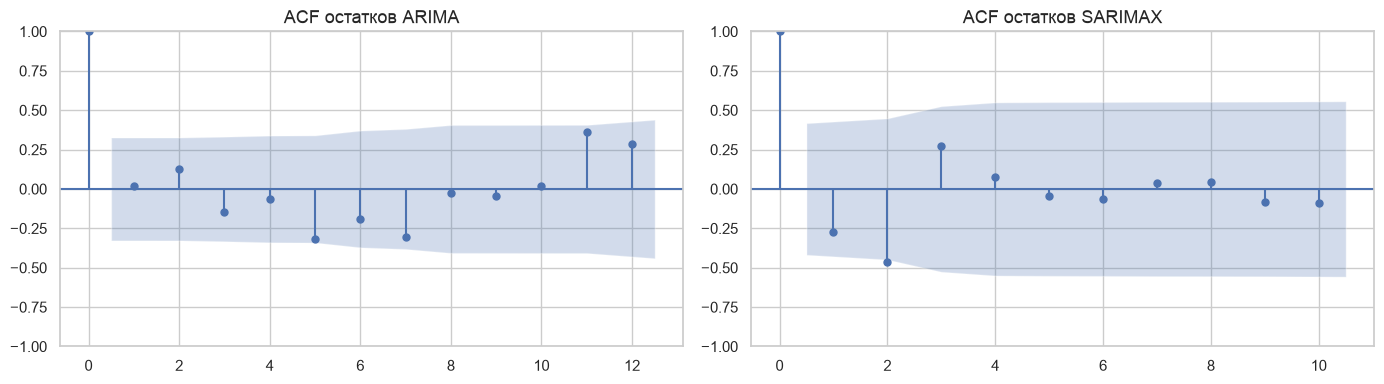

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for row, (name, residuals) in enumerate([
    ("ARIMA", arima_resid),
    ("SARIMAX", sarimax_resid)
]):
    axes[row, 0].plot(residuals.values, marker="o", linewidth=1)
    axes[row, 0].axhline(0, color="red", linestyle="--")
    axes[row, 0].set_title(f"{name}: остатки во времени")

    sns.histplot(residuals, kde=True, ax=axes[row, 1], color="steelblue")
    axes[row, 1].set_title(f"{name}: распределение")

    stats.probplot(residuals, dist="norm", plot=axes[row, 2])
    axes[row, 2].set_title(f"{name}: Q–Q plot")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(arima_resid, lags=min(12, len(arima_resid) // 2 - 1), ax=axes[0])
plot_acf(sarimax_resid, lags=min(10, len(sarimax_resid) // 2 - 1), ax=axes[1])
axes[0].set_title("ACF остатков ARIMA")
axes[1].set_title("ACF остатков SARIMAX")
plt.tight_layout()
plt.show()

### Итоговый прогноз на следующие 12 месяцев

После сравнения модель-победитель обучается на всех 48 наблюдениях. Для будущих внешних признаков нужен сценарий. В демонстрационном сценарии акции не запланированы, а декабрь отмечен как праздничный месяц. Если появится реальный календарь акций, достаточно изменить `future_exog`.

,Прогноз,Нижняя граница 95%,Верхняя граница 95%,Promotion,HolidayMonth
2024-01-01,"15,256.000","13,323.000","17,189.000",0,0
2024-02-01,"15,841.000","13,651.000","18,031.000",0,0
2024-03-01,"15,323.000","12,696.000","17,951.000",0,0
2024-04-01,"14,034.000","11,122.000","16,946.000",0,0
2024-05-01,"12,179.000","8,971.000","15,388.000",0,0
2024-06-01,"11,241.000","7,778.000","14,704.000",0,0
2024-07-01,"12,259.000","8,552.000","15,967.000",0,0
2024-08-01,"13,882.000","9,949.000","17,816.000",0,0
2024-09-01,"14,168.000","10,019.000","18,317.000",0,0
2024-10-01,"14,397.000","10,044.000","18,749.000",0,0


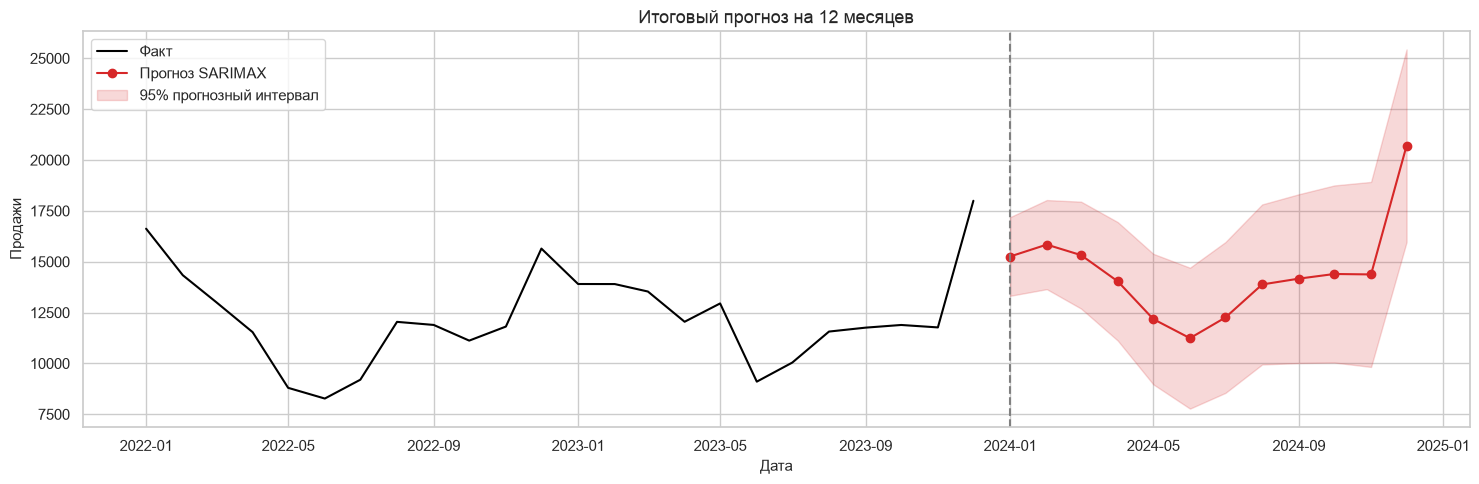

In [22]:
future_index = pd.date_range(target.index.max() + pd.offsets.MonthBegin(1), periods=12, freq="MS")
future_exog = pd.DataFrame({
    "Promotion": np.zeros(12, dtype=int),
    "HolidayMonth": (future_index.month == 12).astype(int)
}, index=future_index)

final_model = SARIMAX(
    target,
    exog=exog,
    order=best_sarimax_order,
    seasonal_order=best_seasonal_order,
    trend="t",
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=200)

future_result = final_model.get_forecast(12, exog=future_exog)
future_forecast = future_result.predicted_mean
future_ci = future_result.conf_int(alpha=0.05)

future_table = pd.DataFrame({
    "Прогноз": future_forecast,
    "Нижняя граница 95%": future_ci.iloc[:, 0],
    "Верхняя граница 95%": future_ci.iloc[:, 1],
    "Promotion": future_exog["Promotion"],
    "HolidayMonth": future_exog["HolidayMonth"]
})
display(future_table.round(0))

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(target.iloc[-24:], label="Факт", color="black")
ax.plot(future_forecast, label="Прогноз SARIMAX", color="tab:red", marker="o")
ax.fill_between(
    future_ci.index,
    future_ci.iloc[:, 0],
    future_ci.iloc[:, 1],
    color="tab:red", alpha=0.18, label="95% прогнозный интервал"
)
ax.axvline(future_index[0], color="gray", linestyle="--")
ax.set(title="Итоговый прогноз на 12 месяцев", xlabel="Дата", ylabel="Продажи")
ax.legend()
plt.tight_layout()
plt.show()

### Вывод по пункту 5 и общий итог

На тестовых данных SARIMAX заметно лучше ARIMA и сезонного наивного прогноза. Для выбранной SARIMAX MSE составляет примерно **1,37 млн**, а R² - около **0,70**, у ARIMA MSE около **4,19 млн**, R² - около **0,09**, SARIMAX также имеет более низкие AIC и BIC. Разница объясняется тем, что SARIMAX явно учитывает годовую сезонность и внешние признаки.

По тестам остатков обе модели не показывают статистически значимой автокорреляции, отклонения от нормальности или ARCH-эффекта на уровне значимости 0,05. У SARIMAX остатки имеют меньший разброс. Поэтому предпочтительной моделью является **SARIMAX(1,1,0)×(0,1,0,12)** с признаками акции и праздничного месяца.

Ограничение работы - всего 48 наблюдений. Прогноз дальше 12 месяцев был бы слишком неопределённым. При накоплении новых данных модель желательно регулярно переобучать и повторно проверять её остатки.